<a href="https://colab.research.google.com/github/aranavkumar/Veloura/blob/main/02_Veloura_Dataset_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import os

PROJECT_ROOT = "/content/drive/MyDrive/Veloura_Project"

TRAIN_DIR = os.path.join(PROJECT_ROOT, "datasets/training")
EVAL_DIR = os.path.join(PROJECT_ROOT, "datasets/evaluation")

os.makedirs(TRAIN_DIR, exist_ok=True)
os.makedirs(EVAL_DIR, exist_ok=True)

print("Training directory:", TRAIN_DIR)
print("Evaluation directory:", EVAL_DIR)
print("Drive connection and paths configured!")


Mounted at /content/drive
Training directory: /content/drive/MyDrive/Veloura_Project/datasets/training
Evaluation directory: /content/drive/MyDrive/Veloura_Project/datasets/evaluation
Drive connection and paths configured!


In [ ]:

import os

def find_archives(folder):
    files = []
    for root, dirs, filenames in os.walk(folder):
        for filename in filenames:
            if filename.lower().endswith((".zip", ".tar", ".tar.gz", ".tgz")):
                path = os.path.join(root, filename)
                files.append(path)
    return files

training_archives = find_archives(TRAIN_DIR)
evaluation_archives = find_archives(EVAL_DIR)

print("========== DATASET FILE INSPECTION ==========")

print("\nTRAINING ARCHIVES:")
for file in training_archives:
    print(file, "|", round(os.path.getsize(file) / (1024**2), 2), "MB")

print("\nEVALUATION ARCHIVES:")
for file in evaluation_archives:
    print(file, "|", round(os.path.getsize(file) / (1024**2), 2), "MB")

print("\n=============================================")


========== DATASET FILE INSPECTION ==========

TRAINING ARCHIVES:
/content/drive/MyDrive/Veloura_Project/datasets/training/health-training.zip | 2054.12 MB

EVALUATION ARCHIVES:
/content/drive/MyDrive/Veloura_Project/datasets/evaluation/health-eval.zip | 509.22 MB



In [ ]:

import zipfile
import os

def inspect_zip(zip_path, max_items=30):
    print("\nARCHIVE:", os.path.basename(zip_path))

    with zipfile.ZipFile(zip_path, "r") as z:
        members = z.infolist()

        print("Total archive entries:", len(members))
        print("\nFirst entries:")

        for item in members[:max_items]:
            print(item.filename)

        print("\nTotal uncompressed size:",
              round(sum(x.file_size for x in members) / (1024**2), 2),
              "MB")

for archive in training_archives + evaluation_archives:
    if archive.lower().endswith(".zip"):
        inspect_zip(archive)



ARCHIVE: health-training.zip
Total archive entries: 7767

First entries:
Health/training/
Health/training/images/
Health/training/images/ISIC_0027404.jpg
Health/training/images/ISIC_0033501.jpg
Health/training/images/ISIC_0030761.jpg
Health/training/images/ISIC_0024979.jpg
Health/training/images/ISIC_0033215.jpg
Health/training/images/ISIC_0032198.jpg
Health/training/images/ISIC_0025063.jpg
Health/training/images/ISIC_0025311.jpg
Health/training/images/ISIC_0024657.jpg
Health/training/images/ISIC_0033817.jpg
Health/training/images/ISIC_0031299.jpg
Health/training/images/ISIC_0032116.jpg
Health/training/images/ISIC_0027107.jpg
Health/training/images/ISIC_0026924.jpg
Health/training/images/ISIC_0033723.jpg
Health/training/images/ISIC_0026995.jpg
Health/training/images/ISIC_0028473.jpg
Health/training/images/ISIC_0030436.jpg
Health/training/images/ISIC_0024677.jpg
Health/training/images/ISIC_0031968.jpg
Health/training/images/ISIC_0024750.jpg
Health/training/images/ISIC_0033350.jpg
Healt

In [ ]:

import os
import zipfile

def safe_extract(zip_path, destination):
    os.makedirs(destination, exist_ok=True)

    root = os.path.realpath(destination)

    with zipfile.ZipFile(zip_path, "r") as archive:
        for member in archive.infolist():

            target = os.path.realpath(
                os.path.join(destination, member.filename)
            )

            if os.path.commonpath([root, target]) != root:
                raise ValueError(
                    f"Unsafe archive path detected: {member.filename}"
                )

        archive.extractall(destination)

    print("Extracted:", os.path.basename(zip_path))
    print("Destination:", destination)

# Run only after confirming the archive names and contents.



In [ ]:

import os

def explore_dataset(root, max_depth=3):
    print("\nDATASET STRUCTURE:", root)

    for current_root, dirs, files in os.walk(root):
        relative = os.path.relpath(current_root, root)
        depth = 0 if relative == "." else relative.count(os.sep) + 1

        if depth > max_depth:
            dirs[:] = []
            continue

        indent = "    " * depth
        print(f"{indent}{os.path.basename(current_root)}/")

        for filename in sorted(files)[:8]:
            print(f"{indent}    {filename}")

        if len(files) > 8:
            print(f"{indent}    ... and {len(files)-8} more files")

        dirs.sort()

# Update these paths if your extraction creates a different structure.
TRAIN_EXTRACTED = os.path.join(TRAIN_DIR, "extracted")
EVAL_EXTRACTED = os.path.join(EVAL_DIR, "extracted")

if os.path.exists(TRAIN_EXTRACTED):
    explore_dataset(TRAIN_EXTRACTED)

if os.path.exists(EVAL_EXTRACTED):
    explore_dataset(EVAL_EXTRACTED)



DATASET STRUCTURE: /content/drive/MyDrive/Veloura_Project/datasets/training/extracted
extracted/

DATASET STRUCTURE: /content/drive/MyDrive/Veloura_Project/datasets/evaluation/extracted
extracted/


In [ ]:

import os
from PIL import Image
from collections import Counter
import pandas as pd

IMAGE_EXTENSIONS = (
    ".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"
)

def inventory_images(root):
    records = []

    for current_root, dirs, files in os.walk(root):
        for filename in files:

            if filename.lower().endswith(IMAGE_EXTENSIONS):
                path = os.path.join(current_root, filename)

                try:
                    with Image.open(path) as img:
                        width, height = img.size

                        records.append({
                            "filename": filename,
                            "relative_path": os.path.relpath(path, root),
                            "directory": os.path.relpath(current_root, root),
                            "format": img.format,
                            "width": width,
                            "height": height,
                            "mode": img.mode,
                            "status": "VALID"
                        })

                except Exception as error:
                    records.append({
                        "filename": filename,
                        "relative_path": os.path.relpath(path, root),
                        "directory": os.path.relpath(current_root, root),
                        "format": None,
                        "width": None,
                        "height": None,
                        "mode": None,
                        "status": "CORRUPTED"
                    })

    return pd.DataFrame(records)

train_inventory = inventory_images(TRAIN_EXTRACTED)
eval_inventory = inventory_images(EVAL_EXTRACTED)

print("TRAINING IMAGES:", len(train_inventory))
print("EVALUATION IMAGES:", len(eval_inventory))

print("\nTRAINING IMAGE STATUS:")
print(train_inventory["status"].value_counts())

print("\nEVALUATION IMAGE STATUS:")
print(eval_inventory["status"].value_counts())

print("\nTRAINING IMAGE FORMATS:")
print(train_inventory["format"].value_counts(dropna=False))

print("\nTRAINING IMAGE DIMENSIONS:")
print(train_inventory.groupby(
    ["width", "height"], dropna=False
).size().sort_values(ascending=False).head(15))


TRAINING IMAGES: 0
EVALUATION IMAGES: 0

TRAINING IMAGE STATUS:


KeyError: 'status'

In [ ]:
import os

print("========== DATASET FOLDER CHECK ==========")

print("\nTRAINING DIRECTORY:")
print(TRAIN_DIR)
print("Exists:", os.path.exists(TRAIN_DIR))

print("\nFiles and folders inside TRAINING:")
for item in os.listdir(TRAIN_DIR):
    path = os.path.join(TRAIN_DIR, item)
    if os.path.isfile(path):
        print("FILE:", item)
    else:
        print("FOLDER:", item)

print("\nEVALUATION DIRECTORY:")
print(EVAL_DIR)
print("Exists:", os.path.exists(EVAL_DIR))

print("\nFiles and folders inside EVALUATION:")
for item in os.listdir(EVAL_DIR):
    path = os.path.join(EVAL_DIR, item)
    if os.path.isfile(path):
        print("FILE:", item)
    else:
        print("FOLDER:", item)

print("\n========== EXTRACTED FOLDER CHECK ==========")

for folder in [TRAIN_EXTRACTED, EVAL_EXTRACTED]:
    print("\nFolder:", folder)
    print("Exists:", os.path.exists(folder))

    if os.path.exists(folder):
        for root, dirs, files in os.walk(folder):
            print("Location:", root)
            print("Subfolders:", dirs[:10])
            print("Files:", files[:10])
            if root.count(os.sep) - folder.count(os.sep) >= 3:
                dirs[:] = []

========== DATASET FOLDER CHECK ==========

TRAINING DIRECTORY:
/content/drive/MyDrive/Veloura_Project/datasets/training
Exists: True

Files and folders inside TRAINING:
FILE: health-training.zip
FOLDER: extracted

EVALUATION DIRECTORY:
/content/drive/MyDrive/Veloura_Project/datasets/evaluation
Exists: True

Files and folders inside EVALUATION:
FILE: health-eval.zip
FOLDER: extracted

========== EXTRACTED FOLDER CHECK ==========

Folder: /content/drive/MyDrive/Veloura_Project/datasets/training/extracted
Exists: True
Location: /content/drive/MyDrive/Veloura_Project/datasets/training/extracted
Subfolders: []
Files: []

Folder: /content/drive/MyDrive/Veloura_Project/datasets/evaluation/extracted
Exists: True
Location: /content/drive/MyDrive/Veloura_Project/datasets/evaluation/extracted
Subfolders: []
Files: []


In [ ]:
import os
import zipfile

training_zip = os.path.join(TRAIN_DIR, "health-training.zip")
evaluation_zip = os.path.join(EVAL_DIR, "health-eval.zip")

def inspect_dataset_zip(zip_path):
    print("\n" + "=" * 60)
    print("ARCHIVE:", os.path.basename(zip_path))
    print("SIZE:", round(os.path.getsize(zip_path) / (1024**2), 2), "MB")

    try:
        with zipfile.ZipFile(zip_path, "r") as archive:
            members = archive.infolist()

            print("ZIP FILE IS VALID")
            print("Total entries:", len(members))
            print("\nFIRST 30 ENTRIES:")

            for item in members[:30]:
                print(item.filename)

            image_extensions = (
                ".jpg", ".jpeg", ".png",
                ".bmp", ".webp", ".tif", ".tiff"
            )

            image_files = [
                item.filename for item in members
                if item.filename.lower().endswith(image_extensions)
            ]

            print("\nTOTAL IMAGE FILES:", len(image_files))
            print("TOTAL UNCOMPRESSED SIZE:",
                  round(sum(x.file_size for x in members) / (1024**2), 2),
                  "MB")

    except zipfile.BadZipFile:
        print("ERROR: This is not a valid ZIP archive.")

inspect_dataset_zip(training_zip)
inspect_dataset_zip(evaluation_zip)


ARCHIVE: health-training.zip
SIZE: 2054.12 MB
ZIP FILE IS VALID
Total entries: 7767

FIRST 30 ENTRIES:
Health/training/
Health/training/images/
Health/training/images/ISIC_0027404.jpg
Health/training/images/ISIC_0033501.jpg
Health/training/images/ISIC_0030761.jpg
Health/training/images/ISIC_0024979.jpg
Health/training/images/ISIC_0033215.jpg
Health/training/images/ISIC_0032198.jpg
Health/training/images/ISIC_0025063.jpg
Health/training/images/ISIC_0025311.jpg
Health/training/images/ISIC_0024657.jpg
Health/training/images/ISIC_0033817.jpg
Health/training/images/ISIC_0031299.jpg
Health/training/images/ISIC_0032116.jpg
Health/training/images/ISIC_0027107.jpg
Health/training/images/ISIC_0026924.jpg
Health/training/images/ISIC_0033723.jpg
Health/training/images/ISIC_0026995.jpg
Health/training/images/ISIC_0028473.jpg
Health/training/images/ISIC_0030436.jpg
Health/training/images/ISIC_0024677.jpg
Health/training/images/ISIC_0031968.jpg
Health/training/images/ISIC_0024750.jpg
Health/training

In [ ]:
import zipfile
import os

def inspect_non_image_files(zip_path):
    print("\n==========",
          os.path.basename(zip_path),
          "==========")

    with zipfile.ZipFile(zip_path, "r") as archive:

        for item in archive.infolist():

            if item.is_dir():
                continue

            filename = item.filename.lower()

            if not filename.endswith(
                (".jpg", ".jpeg", ".png", ".bmp",
                 ".webp", ".tif", ".tiff")
            ):
                print(
                    "OTHER FILE:",
                    item.filename,
                    "|",
                    round(item.file_size / 1024, 2),
                    "KB"
                )

inspect_non_image_files(training_zip)
inspect_non_image_files(evaluation_zip)


========== health-training.zip ==========
OTHER FILE: Health/training/metadata.csv | 366.71 KB
OTHER FILE: README.md | 2.0 KB
OTHER FILE: manifest.json | 4.65 KB

========== health-eval.zip ==========
OTHER FILE: Health/eval/metadata.csv | 91.73 KB
OTHER FILE: README.md | 2.0 KB
OTHER FILE: manifest.json | 4.65 KB


In [ ]:
import zipfile
import pandas as pd
import json

def inspect_metadata(zip_path, metadata_path):

    print("\n" + "=" * 65)
    print("INSPECTING:", metadata_path)
    print("=" * 65)

    with zipfile.ZipFile(zip_path, "r") as archive:

        # Read metadata CSV directly from ZIP
        with archive.open(metadata_path) as file:
            df = pd.read_csv(file)

        print("\nDATASET SHAPE:")
        print(df.shape)

        print("\nCOLUMN NAMES:")
        print(df.columns.tolist())

        print("\nFIRST 5 ROWS:")
        print(df.head().to_string())

        print("\nDATA TYPES:")
        print(df.dtypes)

        print("\nMISSING VALUES:")
        print(df.isnull().sum())

        print("\nUNIQUE VALUES IN EACH COLUMN:")
        for column in df.columns:
            print(
                f"\n{column}:",
                df[column].nunique(),
                "unique values"
            )

        return df


train_metadata = inspect_metadata(
    training_zip,
    "Health/training/metadata.csv"
)

eval_metadata = inspect_metadata(
    evaluation_zip,
    "Health/eval/metadata.csv"
)


INSPECTING: Health/training/metadata.csv

DATASET SHAPE:
(7762, 6)

COLUMN NAMES:
['image_id', 'lesion_id', 'dx', 'age', 'sex', 'localization']

FIRST 5 ROWS:
       image_id    lesion_id   dx   age     sex localization
0  ISIC_0027419  HAM_0000118  bkl  80.0    male        scalp
1  ISIC_0025030  HAM_0000118  bkl  80.0    male        scalp
2  ISIC_0031633  HAM_0001466  bkl  75.0    male          ear
3  ISIC_0027850  HAM_0001466  bkl  75.0    male          ear
4  ISIC_0025837  HAM_0005132  bkl  70.0  female         back

DATA TYPES:
image_id         object
lesion_id        object
dx               object
age             float64
sex              object
localization     object
dtype: object

MISSING VALUES:
image_id         0
lesion_id        0
dx               0
age             43
sex              0
localization     0
dtype: int64

UNIQUE VALUES IN EACH COLUMN:

image_id: 7762 unique values

lesion_id: 5815 unique values

dx: 7 unique values

age: 18 unique values

sex: 3 unique values



In [ ]:
import zipfile

def inspect_documentation(zip_path):

    with zipfile.ZipFile(zip_path, "r") as archive:

        print("\n========== README.md ==========")

        with archive.open("README.md") as file:
            print(file.read().decode("utf-8"))

        print("\n========== manifest.json ==========")

        with archive.open("manifest.json") as file:
            manifest = json.load(file)

            print(json.dumps(manifest, indent=4))


inspect_documentation(training_zip)


========== README.md ==========
# Participant Data Pack

This directory contains the data released to participants. Every track is split into
`training/` and `eval/`. The hidden evaluation inputs are **not** included here; the
organizers release them separately at the scheduled time. No hidden labels are present in
this pack.

Integrity hashes and exact counts are in `manifest.json`.

---

## Cyber — CICIDS2017, five classes

| Partition | File | Rows |
|---|---|---:|
| Training | `Cyber/training/flows.parquet` | 456,737 |
| Eval | `Cyber/eval/flows.parquet` | 114,185 |

Columns: `record_id`, 78 numeric flow features, `label`.

| Class | Training | Eval |
|---|---:|---:|
| `BENIGN` | 240,000 | 60,001 |
| `BRUTE_FORCE` | 5,537 | 1,384 |
| `DOS` | 96,000 | 24,000 |
| `DDOS` | 57,600 | 14,400 |
| `PORT_SCAN` | 57,600 | 14,400 |

The two partitions are disjoint by source record. Flow endpoint metadata (`source_ip`,
`destination_ip`, ports, protocol, `seq`) is intentionally absent from thi

In [ ]:
import os
import zipfile

def safe_extract(zip_path, destination):
    os.makedirs(destination, exist_ok=True)

    root = os.path.realpath(destination)

    with zipfile.ZipFile(zip_path, "r") as archive:

        # Check archive paths before extraction
        for member in archive.infolist():
            target = os.path.realpath(
                os.path.join(destination, member.filename)
            )

            if os.path.commonpath([root, target]) != root:
                raise ValueError(
                    f"Unsafe archive path: {member.filename}"
                )

        archive.extractall(destination)

    print("Successfully extracted:", os.path.basename(zip_path))
    print("Destination:", destination)


TRAIN_EXTRACTED = os.path.join(TRAIN_DIR, "extracted")
EVAL_EXTRACTED = os.path.join(EVAL_DIR, "extracted")

print("Starting training dataset extraction...")
safe_extract(training_zip, TRAIN_EXTRACTED)

print("\nStarting evaluation dataset extraction...")
safe_extract(evaluation_zip, EVAL_EXTRACTED)

print("\nBoth datasets extracted successfully!")

Starting training dataset extraction...
Successfully extracted: health-training.zip
Destination: /content/drive/MyDrive/Veloura_Project/datasets/training/extracted

Starting evaluation dataset extraction...
Successfully extracted: health-eval.zip
Destination: /content/drive/MyDrive/Veloura_Project/datasets/evaluation/extracted

Both datasets extracted successfully!


In [ ]:
import os
import pandas as pd

TRAIN_IMAGE_DIR = os.path.join(
    TRAIN_EXTRACTED, "Health", "training", "images"
)

EVAL_IMAGE_DIR = os.path.join(
    EVAL_EXTRACTED, "Health", "eval", "images"
)

TRAIN_METADATA_PATH = os.path.join(
    TRAIN_EXTRACTED, "Health", "training", "metadata.csv"
)

EVAL_METADATA_PATH = os.path.join(
    EVAL_EXTRACTED, "Health", "eval", "metadata.csv"
)

train_metadata = pd.read_csv(TRAIN_METADATA_PATH)
eval_metadata = pd.read_csv(EVAL_METADATA_PATH)

def count_images(folder):
    extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
    return sum(
        1 for filename in os.listdir(folder)
        if filename.lower().endswith(extensions)
    )

print("TRAINING IMAGES:", count_images(TRAIN_IMAGE_DIR))
print("TRAINING METADATA ROWS:", len(train_metadata))

print("\nEVALUATION IMAGES:", count_images(EVAL_IMAGE_DIR))
print("EVALUATION METADATA ROWS:", len(eval_metadata))

print("\nTRAINING CLASS DISTRIBUTION:")
print(train_metadata["dx"].value_counts())

print("\nEVALUATION CLASS DISTRIBUTION:")
print(eval_metadata["dx"].value_counts())

print("\nMISSING VALUES:")
print("Training age:", train_metadata["age"].isna().sum())
print("Evaluation age:", eval_metadata["age"].isna().sum())

TRAINING IMAGES: 7762
TRAINING METADATA ROWS: 7762

EVALUATION IMAGES: 1942
EVALUATION METADATA ROWS: 1942

TRAINING CLASS DISTRIBUTION:
dx
nv       5212
mel       856
bkl       848
bcc       400
akiec     249
vasc      109
df         88
Name: count, dtype: int64

EVALUATION CLASS DISTRIBUTION:
dx
nv       1302
mel       214
bkl       212
bcc       101
akiec      63
vasc       27
df         23
Name: count, dtype: int64

MISSING VALUES:
Training age: 43
Evaluation age: 12


In [ ]:
import os

def check_image_mapping(metadata, image_dir):
    available_images = set(os.listdir(image_dir))

    expected_images = set(
        metadata["image_id"].astype(str) + ".jpg"
    )

    missing = expected_images - available_images
    extra = available_images - expected_images

    print("Expected images:", len(expected_images))
    print("Available matching images:", len(expected_images & available_images))
    print("Missing images:", len(missing))
    print("Extra files:", len(extra))

    if missing:
        print("First missing filenames:", list(missing)[:10])

    return len(missing) == 0


print("TRAINING IMAGE MAPPING")
train_mapping_ok = check_image_mapping(
    train_metadata, TRAIN_IMAGE_DIR
)

print("\nEVALUATION IMAGE MAPPING")
eval_mapping_ok = check_image_mapping(
    eval_metadata, EVAL_IMAGE_DIR
)

print("\nLESION OVERLAP CHECK")

train_lesions = set(train_metadata["lesion_id"])
eval_lesions = set(eval_metadata["lesion_id"])

overlap = train_lesions.intersection(eval_lesions)

print("Training unique lesions:", len(train_lesions))
print("Evaluation unique lesions:", len(eval_lesions))
print("Overlapping lesions:", len(overlap))

print("\nFINAL CHECKS")
print("Training mapping:", train_mapping_ok)
print("Evaluation mapping:", eval_mapping_ok)
print("Lesion separation:", len(overlap) == 0)

TRAINING IMAGE MAPPING
Expected images: 7762
Available matching images: 7762
Missing images: 0
Extra files: 0

EVALUATION IMAGE MAPPING
Expected images: 1942
Available matching images: 1942
Missing images: 0
Extra files: 0

LESION OVERLAP CHECK
Training unique lesions: 5815
Evaluation unique lesions: 1456
Overlapping lesions: 0

FINAL CHECKS
Training mapping: True
Evaluation mapping: True
Lesion separation: True


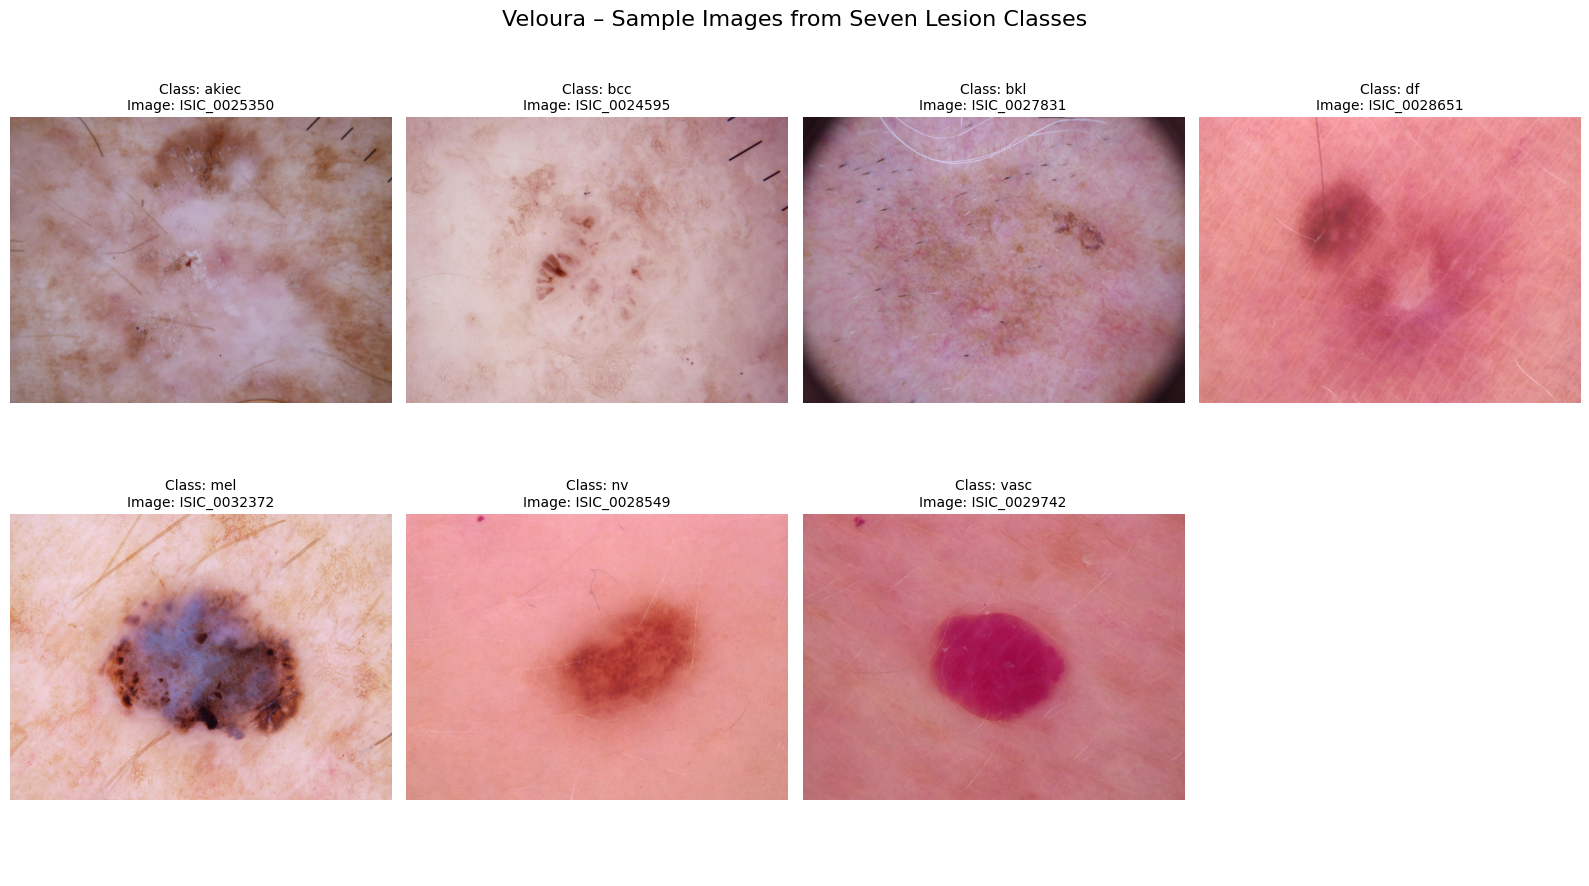

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os
import random

class_names = sorted(train_metadata["dx"].unique())

fig, axes = plt.subplots(2, 4, figsize=(16, 9))
axes = axes.flatten()

for i, class_name in enumerate(class_names):

    sample = train_metadata[
        train_metadata["dx"] == class_name
    ].sample(1, random_state=42).iloc[0]

    image_path = os.path.join(
        TRAIN_IMAGE_DIR,
        sample["image_id"] + ".jpg"
    )

    image = Image.open(image_path).convert("RGB")

    axes[i].imshow(image)
    axes[i].set_title(
        f"Class: {class_name}\nImage: {sample['image_id']}",
        fontsize=10
    )
    axes[i].axis("off")

axes[7].axis("off")

plt.suptitle(
    "Veloura – Sample Images from Seven Lesion Classes",
    fontsize=16
)
plt.tight_layout()
plt.show()

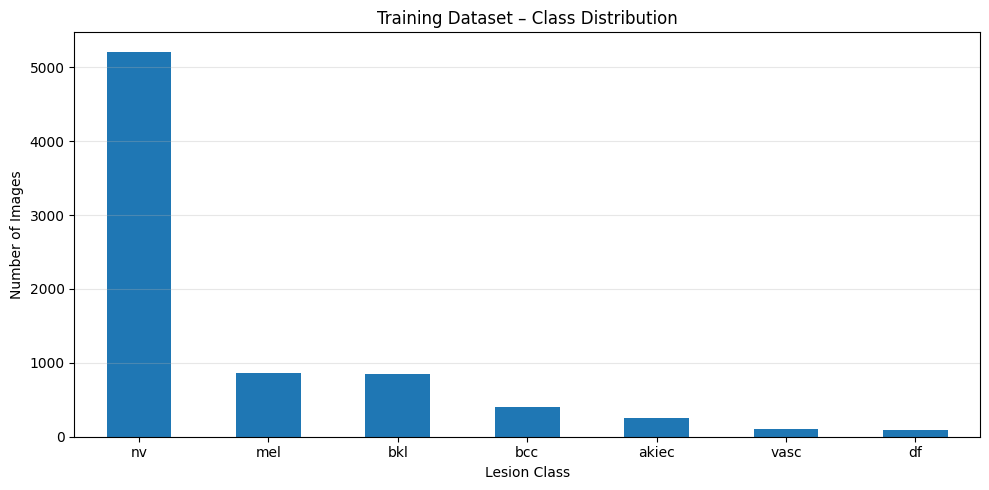

In [ ]:
import matplotlib.pyplot as plt

class_counts = train_metadata["dx"].value_counts()

plt.figure(figsize=(10, 5))
class_counts.plot(kind="bar")

plt.title("Training Dataset – Class Distribution")
plt.xlabel("Lesion Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
from PIL import Image
import os
import pandas as pd

image_records = []

for filename in os.listdir(TRAIN_IMAGE_DIR):

    if not filename.lower().endswith(".jpg"):
        continue

    path = os.path.join(TRAIN_IMAGE_DIR, filename)

    try:
        with Image.open(path) as img:
            image_records.append({
                "filename": filename,
                "width": img.width,
                "height": img.height,
                "format": img.format,
                "status": "VALID"
            })

    except Exception as error:
        image_records.append({
            "filename": filename,
            "width": None,
            "height": None,
            "format": None,
            "status": "CORRUPTED"
        })

image_report = pd.DataFrame(image_records)

print("Total inspected:", len(image_report))
print("\nImage status:")
print(image_report["status"].value_counts())

print("\nMost common image dimensions:")
print(
    image_report.groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
    .head(10)
)

print("\nImage dimensions summary:")
print(image_report[["width", "height"]].describe())

Total inspected: 7762

Image status:
status
VALID    7762
Name: count, dtype: int64

Most common image dimensions:
width  height
600    450       7762
dtype: int64

Image dimensions summary:
        width  height
count  7762.0  7762.0
mean    600.0   450.0
std       0.0     0.0
min     600.0   450.0
25%     600.0   450.0
50%     600.0   450.0
75%     600.0   450.0
max     600.0   450.0


In [ ]:
import os

REPORT_DIR = os.path.join(
    PROJECT_ROOT,
    "reports",
    "dataset_analysis"
)

os.makedirs(REPORT_DIR, exist_ok=True)

train_metadata.to_csv(
    os.path.join(REPORT_DIR, "training_metadata.csv"),
    index=False
)

eval_metadata.to_csv(
    os.path.join(REPORT_DIR, "evaluation_metadata.csv"),
    index=False
)

image_report.to_csv(
    os.path.join(REPORT_DIR, "training_image_quality_inventory.csv"),
    index=False
)

print("Phase 2 reports saved successfully!")
print("Location:", REPORT_DIR)

Phase 2 reports saved successfully!
Location: /content/drive/MyDrive/Veloura_Project/reports/dataset_analysis
